In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from collections import defaultdict
from itertools import combinations

print('Library berhasil diimport!')

Library berhasil diimport!


In [2]:
df = pd.read_csv('/kaggle/input/datasets/akashdeepkuila/bakery/Bakery.csv')

print(f'Jumlah baris   : {df.shape[0]:,}')
print(f'Jumlah kolom   : {df.shape[1]}')
print(f'Kolom          : {df.columns.tolist()}')
print()
df.head(10)

Jumlah baris   : 20,507
Jumlah kolom   : 5
Kolom          : ['TransactionNo', 'Items', 'DateTime', 'Daypart', 'DayType']



,TransactionNo,Items,DateTime,Daypart,DayType
0,1,Bread,2016-10-30 09:58:11,Morning,Weekend
1,2,Scandinavian,2016-10-30 10:05:34,Morning,Weekend
2,2,Scandinavian,2016-10-30 10:05:34,Morning,Weekend
3,3,Hot chocolate,2016-10-30 10:07:57,Morning,Weekend
4,3,Jam,2016-10-30 10:07:57,Morning,Weekend
5,3,Cookies,2016-10-30 10:07:57,Morning,Weekend
6,4,Muffin,2016-10-30 10:08:41,Morning,Weekend
7,5,Coffee,2016-10-30 10:13:03,Morning,Weekend
8,5,Pastry,2016-10-30 10:13:03,Morning,Weekend
9,5,Bread,2016-10-30 10:13:03,Morning,Weekend


# **Data Understanding**

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20507 entries, 0 to 20506
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   TransactionNo  20507 non-null  int64 
 1   Items          20507 non-null  object
 2   DateTime       20507 non-null  object
 3   Daypart        20507 non-null  object
 4   DayType        20507 non-null  object
dtypes: int64(1), object(4)
memory usage: 801.2+ KB


In [4]:
df.describe(include='all')

,TransactionNo,Items,DateTime,Daypart,DayType
count,20507.000000,20507,20507,20507,20507
unique,NaN,94,9465,4,2
top,NaN,Coffee,2017-09-02 13:44:56,Afternoon,Weekday
freq,NaN,5471,11,11569,12807
mean,4976.202370,NaN,NaN,NaN,NaN
std,2796.203001,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN
25%,2552.000000,NaN,NaN,NaN,NaN
50%,5137.000000,NaN,NaN,NaN,NaN
75%,7357.000000,NaN,NaN,NaN,NaN


In [5]:
# Cek Missing Values

missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing (%)': missing_pct
})
print(missing_df)
print()
if missing.sum() == 0:
    print('Tidak ada missing values pada dataset ini.')
else:
    print(f'Total missing values: {missing.sum()}')

               Missing Count  Missing (%)
TransactionNo              0          0.0
Items                      0          0.0
DateTime                   0          0.0
Daypart                    0          0.0
DayType                    0          0.0

Tidak ada missing values pada dataset ini.


### Cell 5 — Cek Duplicate

In [6]:
# Cek Duplikat
n_dup_full = df.duplicated().sum()
n_dup_tx_item = df.duplicated(subset=['TransactionNo', 'Items']).sum()

print(f'Duplicate baris penuh (semua kolom sama) : {n_dup_full:,}')
print(f'Duplicate TransactionNo + Items          : {n_dup_tx_item:,}')
print()

# Tampilkan contoh duplikat
print('Contoh baris duplikat:')
df[df.duplicated(keep=False)].sort_values(['TransactionNo','Items']).head(20)

Duplicate baris penuh (semua kolom sama) : 1,620
Duplicate TransactionNo + Items          : 1,620

Contoh baris duplikat:


,TransactionNo,Items,DateTime,Daypart,DayType
1,2,Scandinavian,2016-10-30 10:05:34,Morning,Weekend
2,2,Scandinavian,2016-10-30 10:05:34,Morning,Weekend
23,11,Bread,2016-10-30 10:27:21,Morning,Weekend
25,11,Bread,2016-10-30 10:27:21,Morning,Weekend
48,21,Coffee,2016-10-30 10:49:29,Morning,Weekend
49,21,Coffee,2016-10-30 10:49:29,Morning,Weekend
100,49,Coffee,2016-10-30 12:23:01,Afternoon,Weekend
101,49,Coffee,2016-10-30 12:23:01,Afternoon,Weekend
121,60,Coffee,2016-10-30 13:14:04,Afternoon,Weekend
123,60,Coffee,2016-10-30 13:14:04,Afternoon,Weekend


**Interpretasi Duplikat:** Terdapat baris dengan `TransactionNo`, `Items`, `DateTime` yang identik. Dalam konteks **Association Rule Mining**, analisis dilakukan berbasis **binary basket** (apakah suatu item ada dalam transaksi atau tidak). Oleh karena itu, pembelian item yang sama dua kali dalam satu transaksi tetap dianggap sebagai satu kemunculan. Duplikat ini akan dihapus pada tahap Data Preparation.

In [7]:
# Eksplorasi Distribusi Item

item_counts = df['Items'].value_counts()
print(f'Total item unik: {item_counts.shape[0]}')
print()
print('20 Item paling sering dibeli:')
print(item_counts.head(20))
print()
print('10 Item paling jarang dibeli:')
print(item_counts.tail(10))

Total item unik: 94

20 Item paling sering dibeli:
Items
Coffee           5471
Bread            3325
Tea              1435
Cake             1025
Pastry            856
Sandwich          771
Medialuna         616
Hot chocolate     590
Cookies           540
Brownie           379
Farm House        374
Muffin            370
Alfajores         369
Juice             369
Soup              342
Scone             327
Toast             318
Scandinavian      277
Truffles          193
Coke              185
Name: count, dtype: int64

10 Item paling jarang dibeli:
Items
Spread            2
Hack the stack    2
Chicken sand      1
Polenta           1
Bacon             1
Adjustment        1
The BART          1
Olum & polenta    1
Gift voucher      1
Raw bars          1
Name: count, dtype: int64


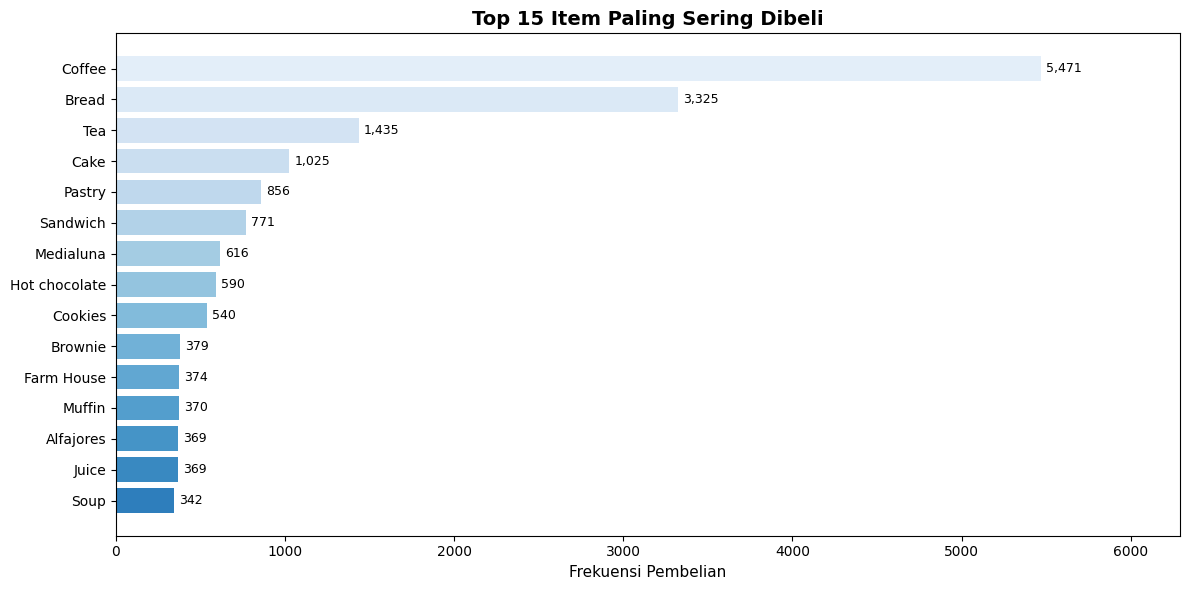

Coffee adalah item terlaris dengan 5,471 transaksi (26.7% dari total baris data).


In [8]:
# Visualisasi Top 15 Item

top15 = item_counts.head(15)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(top15.index[::-1], top15.values[::-1],
               color=plt.cm.Blues_r(np.linspace(0.3, 0.9, 15)))

# Tambahkan label nilai
for bar, val in zip(bars, top15.values[::-1]):
    ax.text(bar.get_width() + 30, bar.get_y() + bar.get_height()/2,
            f'{val:,}', va='center', fontsize=9)

ax.set_xlabel('Frekuensi Pembelian', fontsize=11)
ax.set_title('Top 15 Item Paling Sering Dibeli', fontsize=14, fontweight='bold')
ax.set_xlim(0, top15.values.max() * 1.15)
plt.tight_layout()
plt.show()

print(f'Coffee adalah item terlaris dengan {item_counts["Coffee"]:,} transaksi '
      f'({item_counts["Coffee"]/len(df)*100:.1f}% dari total baris data).')

=== STATISTIK JUMLAH ITEM PER TRANSAKSI ===
count    9465.00
mean        2.17
std         1.30
min         1.00
25%         1.00
50%         2.00
75%         3.00
max        11.00
Name: Items, dtype: float64

Distribusi:
Items
1     3631
2     2908
3     1528
4      850
5      341
6      135
7       38
8       21
9        7
10       2
11       4
Name: count, dtype: int64


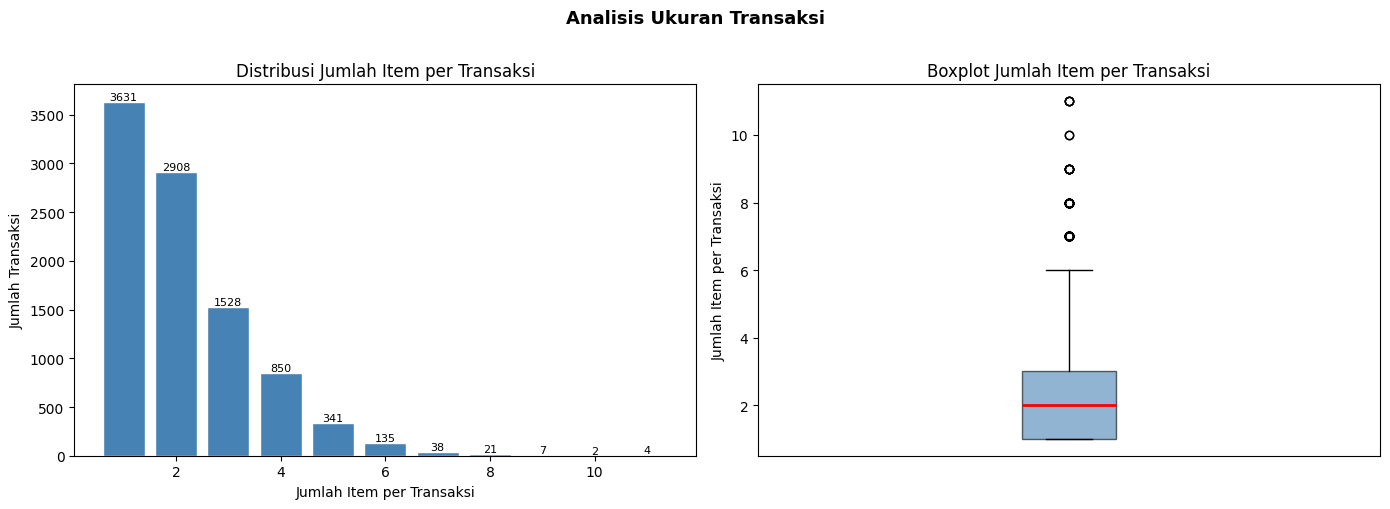

In [9]:
# Jumlah item unik per transaksi 
items_per_tx = df.groupby('TransactionNo')['Items'].count()

print('=== STATISTIK JUMLAH ITEM PER TRANSAKSI ===')
print(items_per_tx.describe().round(2))
print()
print('Distribusi:')
print(items_per_tx.value_counts().sort_index())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart distribusi
dist = items_per_tx.value_counts().sort_index()
axes[0].bar(dist.index, dist.values, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Jumlah Item per Transaksi')
axes[0].set_ylabel('Jumlah Transaksi')
axes[0].set_title('Distribusi Jumlah Item per Transaksi')
for i, (x, y) in enumerate(zip(dist.index, dist.values)):
    axes[0].text(x, y + 20, str(y), ha='center', fontsize=8)

# Boxplot
axes[1].boxplot(items_per_tx.values, vert=True, patch_artist=True,
                boxprops=dict(facecolor='steelblue', alpha=0.6),
                medianprops=dict(color='red', linewidth=2))
axes[1].set_ylabel('Jumlah Item per Transaksi')
axes[1].set_title('Boxplot Jumlah Item per Transaksi')
axes[1].set_xticks([])

plt.suptitle('Analisis Ukuran Transaksi', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

**Interpretasi:** Mayoritas transaksi hanya terdiri dari **1-2 item** (sekitar 70%+). Transaksi dengan banyak item (>6) sangat jarang. Ini adalah pola umum pada toko roti.

Pada Association Rule Mining, **tidak ada konsep outlier** dalam arti statistik seperti pada regresi atau clustering. Transaksi dengan 1 item hanya tidak akan menghasilkan rules (karena rules membutuhkan minimal 2 item), namun tetap berkontribusi pada perhitungan **support** item individual.

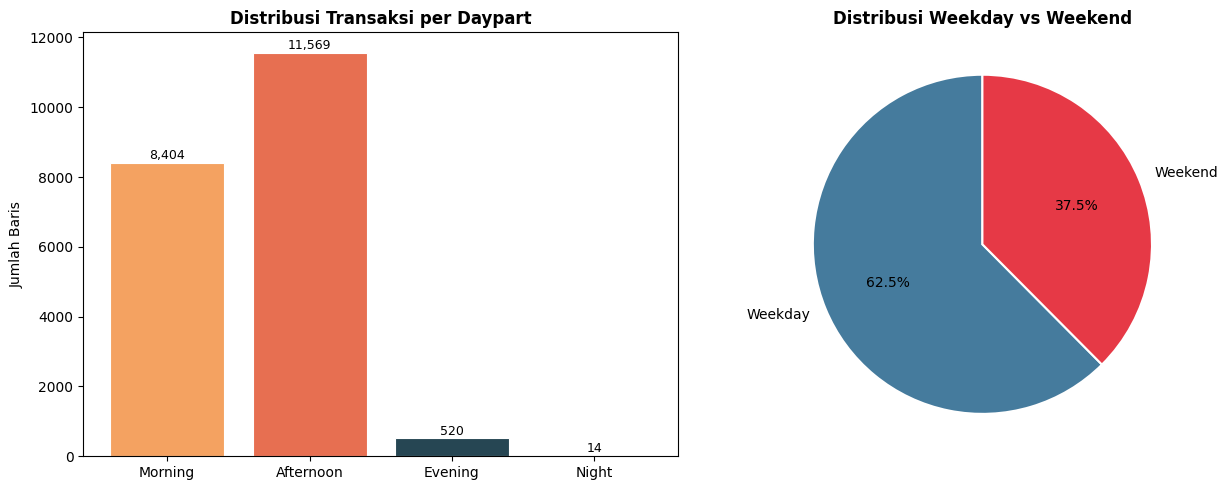

Daypart value counts:
Daypart
Afternoon    11569
Morning       8404
Evening        520
Night           14
Name: count, dtype: int64

DayType value counts:
DayType
Weekday    12807
Weekend     7700
Name: count, dtype: int64


In [10]:
# Distribusi Berdasarkan Daypart dan DayType

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Daypart
daypart_order = ['Morning', 'Afternoon', 'Evening', 'Night']
daypart_counts = df['Daypart'].value_counts().reindex(daypart_order)
colors_dp = ['#f4a261', '#e76f51', '#264653', '#2a9d8f']
bars1 = axes[0].bar(daypart_counts.index, daypart_counts.values,
                    color=colors_dp, edgecolor='white', linewidth=0.8)
axes[0].set_title('Distribusi Transaksi per Daypart', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Jumlah Baris')
for bar in bars1:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
                 f'{bar.get_height():,}', ha='center', fontsize=9)

# DayType
daytype_counts = df['DayType'].value_counts()
axes[1].pie(daytype_counts.values, labels=daytype_counts.index,
            autopct='%1.1f%%', colors=['#457b9d', '#e63946'],
            startangle=90, wedgeprops=dict(edgecolor='white', linewidth=1.5))
axes[1].set_title('Distribusi Weekday vs Weekend', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print('Daypart value counts:')
print(df['Daypart'].value_counts())
print()
print('DayType value counts:')
print(df['DayType'].value_counts())

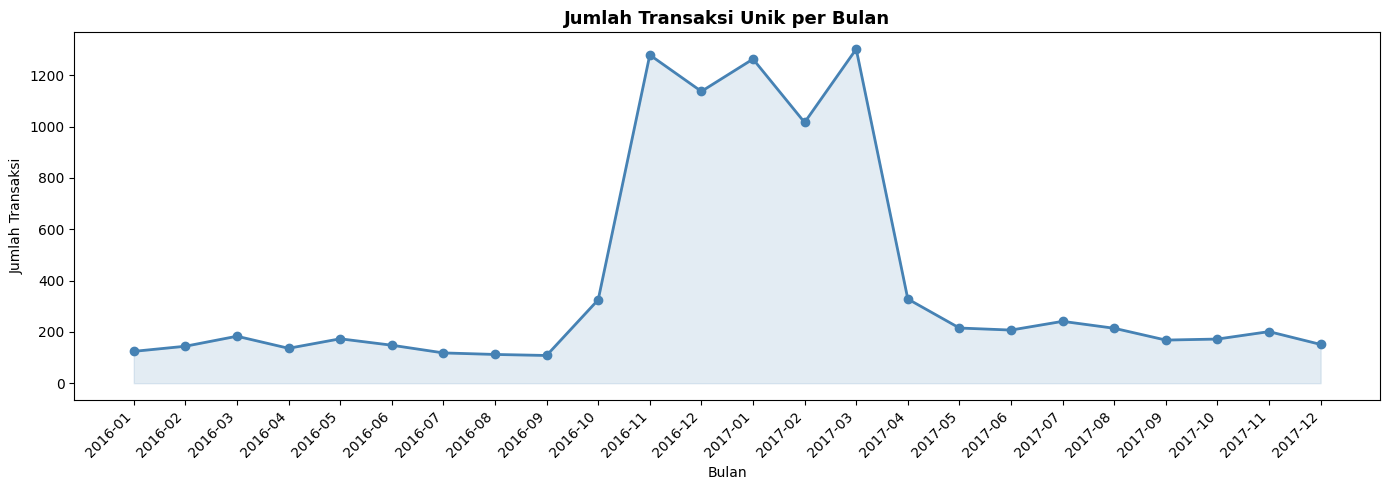

Rentang data: 2016-01-11 07:51:20 sd 2017-12-03 16:28:00


In [11]:
# Distribusi Transaksi per Bulan

df['DateTime'] = pd.to_datetime(df['DateTime'])
df['YearMonth'] = df['DateTime'].dt.to_period('M')

monthly_tx = df.groupby('YearMonth')['TransactionNo'].nunique().reset_index()
monthly_tx.columns = ['YearMonth', 'UniqueTransactions']

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(monthly_tx['YearMonth'].astype(str),
        monthly_tx['UniqueTransactions'],
        marker='o', color='steelblue', linewidth=2, markersize=6)
ax.fill_between(monthly_tx['YearMonth'].astype(str),
                monthly_tx['UniqueTransactions'],
                alpha=0.15, color='steelblue')
ax.set_title('Jumlah Transaksi Unik per Bulan', fontsize=13, fontweight='bold')
ax.set_xlabel('Bulan')
ax.set_ylabel('Jumlah Transaksi')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print('Rentang data:', df['DateTime'].min(), 'sd', df['DateTime'].max())

# **Data Preparation**

### Cell 11 — Hapus Duplikat

In [12]:
# Penanganan Duplikat

print(f'Jumlah baris sebelum drop duplicate: {len(df):,}')

df_clean = df.drop_duplicates(subset=['TransactionNo', 'Items'])

print(f'Jumlah baris setelah drop duplicate  : {len(df_clean):,}')
print(f'Baris yang dihapus                   : {len(df) - len(df_clean):,}')
print(f'Jumlah transaksi unik tetap          : {df_clean["TransactionNo"].nunique():,}')
print()
print('✅ Duplikat berhasil dihapus.')

Jumlah baris sebelum drop duplicate: 20,507
Jumlah baris setelah drop duplicate  : 18,887
Baris yang dihapus                   : 1,620
Jumlah transaksi unik tetap          : 9,465

✅ Duplikat berhasil dihapus.


Total transaksi: 9,465
Total item unik: 94

Item dengan support < 1% (< 94 transaksi): 64 item
Items
Raw bars            0.000106
Gift voucher        0.000106
Olum & polenta      0.000106
The BART            0.000106
Adjustment          0.000106
                      ...   
Focaccia            0.005705
The Nomad           0.006128
Keeping It Local    0.006656
Smoothies           0.008135
Frittata            0.008558
Name: count, Length: 64, dtype: float64



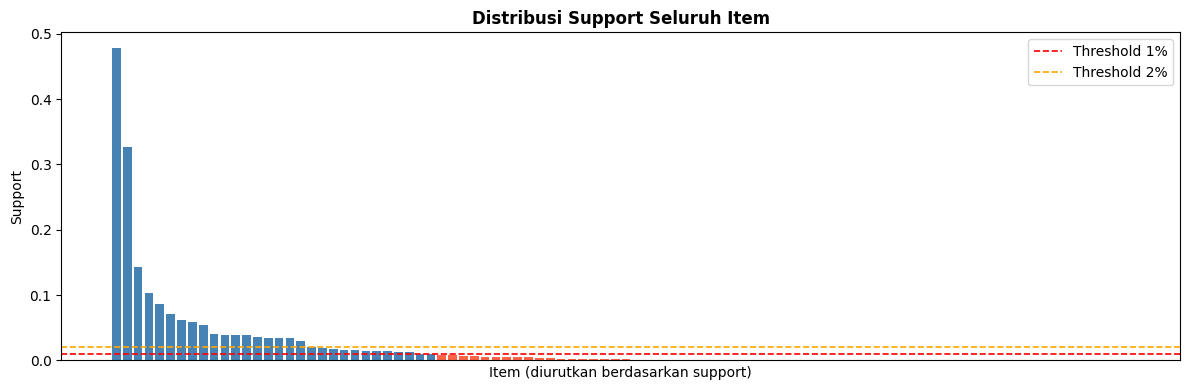

In [13]:
# Analisis Frekuensi Item

TOTAL_TX = df_clean['TransactionNo'].nunique()
item_freq = df_clean['Items'].value_counts()
item_support = item_freq / TOTAL_TX

print(f'Total transaksi: {TOTAL_TX:,}')
print(f'Total item unik: {len(item_freq)}')
print()

# Item dengan support < 1% (muncul < 95 transaksi)
rare_items = item_support[item_support < 0.01]
print(f'Item dengan support < 1% (< {int(0.01*TOTAL_TX)} transaksi): {len(rare_items)} item')
print(rare_items.sort_values())
print()

# Visualisasi distribusi support semua item
fig, ax = plt.subplots(figsize=(12, 4))
sorted_support = item_support.sort_values(ascending=False)
colors = ['tomato' if s < 0.01 else 'steelblue' for s in sorted_support.values]
ax.bar(range(len(sorted_support)), sorted_support.values, color=colors)
ax.axhline(y=0.01, color='red', linestyle='--', linewidth=1.2, label='Threshold 1%')
ax.axhline(y=0.02, color='orange', linestyle='--', linewidth=1.2, label='Threshold 2%')
ax.set_xlabel('Item (diurutkan berdasarkan support)')
ax.set_ylabel('Support')
ax.set_title('Distribusi Support Seluruh Item', fontsize=12, fontweight='bold')
ax.legend()
ax.set_xticks([])
plt.tight_layout()
plt.show()

In [14]:
# Transformasi ke Format Transaksi (Buat daftar transaksi: list of sets)

transactions = df_clean.groupby('TransactionNo')['Items'].apply(set).tolist()

print(f'Jumlah transaksi: {len(transactions)}')
print()
print('Contoh 5 transaksi pertama:')
for i, tx in enumerate(transactions[:5]):
    print(f'  Transaksi {i+1}: {sorted(tx)}')

Jumlah transaksi: 9465

Contoh 5 transaksi pertama:
  Transaksi 1: ['Bread']
  Transaksi 2: ['Scandinavian']
  Transaksi 3: ['Cookies', 'Hot chocolate', 'Jam']
  Transaksi 4: ['Muffin']
  Transaksi 5: ['Bread', 'Coffee', 'Pastry']


In [15]:
# Membangun Vertical TID-Set

# Membangun TID-set untuk setiap item
vertical_db = defaultdict(set)
for tx_id, row in df_clean.groupby('TransactionNo')['Items']:
    for item in row:
        vertical_db[item].add(tx_id)

# Tampilkan contoh TID-set
print('Contoh TID-set untuk 3 item dengan support tertinggi:')
top3_items = item_freq.head(3).index.tolist()
for item in top3_items:
    tids = vertical_db[item]
    support = len(tids) / TOTAL_TX
    print(f'  [{item}]: {len(tids):,} transaksi | support = {support:.4f} ({support*100:.2f}%)')
    print(f'    Contoh TID: {sorted(list(tids))[:5]}...')

print(f'\nTotal item dalam database vertikal: {len(vertical_db)}')

Contoh TID-set untuk 3 item dengan support tertinggi:
  [Coffee]: 4,528 transaksi | support = 0.4784 (47.84%)
    Contoh TID: [5, 7, 12, 13, 16]...
  [Bread]: 3,097 transaksi | support = 0.3272 (32.72%)
    Contoh TID: [1, 5, 8, 9, 11]...
  [Tea]: 1,350 transaksi | support = 0.1426 (14.26%)
    Contoh TID: [7, 12, 36, 38, 42]...

Total item dalam database vertikal: 94


# **Modeling - ECLAT**

### Cell 15 — Penentuan Parameter ECLAT

In [16]:
# Parameter ECLAT
MIN_SUPPORT    = 0.02   # Minimum support: 2% dari total transaksi
MIN_CONFIDENCE = 0.3    # Minimum confidence: 30%

min_support_count = int(MIN_SUPPORT * TOTAL_TX)

print('=== PARAMETER ECLAT ===')
print(f'Total transaksi         : {TOTAL_TX:,}')
print(f'Minimum support         : {MIN_SUPPORT:.0%} = {min_support_count} transaksi')
print(f'Minimum confidence      : {MIN_CONFIDENCE:.0%}')

=== PARAMETER ECLAT ===
Total transaksi         : 9,465
Minimum support         : 2% = 189 transaksi
Minimum confidence      : 30%


In [17]:
# Implementasi ECLAT

def eclat(vertical_db, total_tx, min_support):
    """
    Parameter:
    - vertical_db : dict {item -> set(TID)}
    - total_tx    : total jumlah transaksi
    - min_support : threshold support minimum (0 - 1)
    
    Return:
    - frequent_itemsets : list of (frozenset, support_count)
    """
    
    min_count = min_support * total_tx  # Konversi ke count
    frequent_itemsets = []              # Menyimpan semua frequent itemsets

    def eclat_recursive(prefix, prefix_tids, items_tids):
        for i in range(len(items_tids)):
            item_i, tids_i = items_tids[i]

            # Buat itemset baru: prefix + item_i
            new_itemset = prefix | item_i

            # Interseksi TID-set: TID(prefix ∪ item) = TID(prefix) ∩ TID(item)
            if prefix_tids is not None:
                new_tids = prefix_tids & tids_i
            else:
                new_tids = tids_i

            # Cek apakah memenuhi minimum support
            if len(new_tids) >= min_count:
                # Simpan frequent itemset
                frequent_itemsets.append((new_itemset, len(new_tids)))

                # Rekursif: cari superset dari new_itemset
                # Hanya gunakan item setelah i untuk menghindari duplikat
                suffix_items = items_tids[i+1:]
                if suffix_items:
                    eclat_recursive(new_itemset, new_tids, suffix_items)

    # Step 1: Filter 1-itemsets yang memenuhi min_support
    freq_1_items = [
        (frozenset([item]), tids)
        for item, tids in vertical_db.items()
        if len(tids) >= min_count
    ]

    # Urutkan berdasarkan support (descending) untuk efisiensi
    freq_1_items.sort(key=lambda x: len(x[1]), reverse=True)

    # Step 2: Bangun itemset dengan lebih dari 1 item (rekursif)
    eclat_recursive(frozenset(), None, freq_1_items)

    return frequent_itemsets


print('Fungsi ECLAT berhasil didefinisikan!')

Fungsi ECLAT berhasil didefinisikan!


In [18]:
import time

print('=== MENJALANKAN ALGORITMA ECLAT ===')
print(f'Min support : {MIN_SUPPORT:.0%} ({int(MIN_SUPPORT * TOTAL_TX)} transaksi)')
print()

start_time = time.time()
frequent_itemsets_raw = eclat(vertical_db, TOTAL_TX, MIN_SUPPORT)
elapsed = time.time() - start_time

print(f'✅ ECLAT selesai dalam {elapsed:.3f} detik')
print(f'Total frequent itemsets ditemukan: {len(frequent_itemsets_raw)}')
print()

# Konversi ke DataFrame
fi_data = []
for itemset, count in frequent_itemsets_raw:
    fi_data.append({
        'itemset'       : frozenset(itemset),
        'itemset_str'   : ', '.join(sorted(itemset)),
        'itemset_size'  : len(itemset),
        'support_count' : count,
        'support'       : count / TOTAL_TX
    })

fi_df = pd.DataFrame(fi_data).sort_values('support', ascending=False).reset_index(drop=True)

# Ringkasan per ukuran itemset
print('Ringkasan frequent itemsets per ukuran:')
summary = fi_df.groupby('itemset_size').size().reset_index(name='jumlah')
summary.columns = ['Ukuran Itemset', 'Jumlah Frequent Itemset']
print(summary.to_string(index=False))
print()
print('Contoh frequent itemsets (top 15 berdasarkan support):')
fi_df[['itemset_str', 'itemset_size', 'support_count', 'support']].head(15)

=== MENJALANKAN ALGORITMA ECLAT ===
Min support : 2% (189 transaksi)

✅ ECLAT selesai dalam 0.005 detik
Total frequent itemsets ditemukan: 33

Ringkasan frequent itemsets per ukuran:
 Ukuran Itemset  Jumlah Frequent Itemset
              1                       19
              2                       14

Contoh frequent itemsets (top 15 berdasarkan support):


,itemset_str,itemset_size,support_count,support
0,Coffee,1,4528,0.478394
1,Bread,1,3097,0.327205
2,Tea,1,1350,0.142631
3,Cake,1,983,0.103856
4,"Bread, Coffee",2,852,0.090016
5,Pastry,1,815,0.086107
6,Sandwich,1,680,0.071844
7,Medialuna,1,585,0.061807
8,Hot chocolate,1,552,0.058320
9,"Cake, Coffee",2,518,0.054728


In [19]:
# Implementasi Association Rules Generator

def generate_association_rules(frequent_itemsets_df, total_tx, min_confidence):
    # Buat lookup support dari frequent itemsets
    support_lookup = {
        row['itemset']: row['support']
        for _, row in frequent_itemsets_df.iterrows()
    }

    rules = []

    # Hanya itemset dengan ukuran >= 2 yang bisa menghasilkan rules
    multi_itemsets = frequent_itemsets_df[frequent_itemsets_df['itemset_size'] >= 2]

    for _, row in multi_itemsets.iterrows():
        itemset = row['itemset']
        support_ab = row['support']

        # Generate semua non-empty proper subset sebagai antecedent
        items = list(itemset)
        for r in range(1, len(items)):  # antecedent size: 1 sampai len-1
            for antecedent_tuple in combinations(items, r):
                antecedent = frozenset(antecedent_tuple)
                consequent = itemset - antecedent

                # Support antecedent
                support_a = support_lookup.get(antecedent)
                if support_a is None or support_a == 0:
                    continue

                # Support consequent
                support_b = support_lookup.get(consequent)
                if support_b is None or support_b == 0:
                    continue

                # Hitung metrik
                confidence = support_ab / support_a
                lift       = confidence / support_b

                # Conviction: (1 - support_B) / (1 - confidence)
                if confidence < 1.0:
                    conviction = (1 - support_b) / (1 - confidence)
                else:
                    conviction = float('inf')

                # Filter berdasarkan min_confidence
                if confidence >= min_confidence:
                    rules.append({
                        'antecedent'      : antecedent,
                        'consequent'      : consequent,
                        'antecedent_str'  : ', '.join(sorted(antecedent)),
                        'consequent_str'  : ', '.join(sorted(consequent)),
                        'support'         : support_ab,
                        'confidence'      : confidence,
                        'lift'            : lift,
                        'conviction'      : conviction
                    })

    rules_df = pd.DataFrame(rules).sort_values('lift', ascending=False).reset_index(drop=True)
    return rules_df

print('Fungsi generate_association_rules berhasil didefinisikan!')

Fungsi generate_association_rules berhasil didefinisikan!


In [20]:
# Hasilkan Association Rules

print(f'Min confidence: {MIN_CONFIDENCE:.0%}')
print()

rules_df = generate_association_rules(fi_df, TOTAL_TX, MIN_CONFIDENCE)

print(f'Total rules yang dihasilkan: {len(rules_df)}')
print()

if len(rules_df) == 0:
    print('⚠️ Tidak ada rules yang ditemukan. Coba turunkan min_confidence atau min_support.')
else:
    print(f'Rules dengan lift > 1 (hubungan positif): {(rules_df["lift"] > 1).sum()}')
    print(f'Rules dengan lift > 1.5                : {(rules_df["lift"] > 1.5).sum()}')
    print(f'Rules dengan lift > 2.0                : {(rules_df["lift"] > 2.0).sum()}')
    print()
    print('Top 20 Rules berdasarkan Lift:')
    display_cols = ['antecedent_str', 'consequent_str', 'support', 'confidence', 'lift', 'conviction']
    display(rules_df[display_cols].head(20))

Min confidence: 30%

Total rules yang dihasilkan: 10

Rules dengan lift > 1 (hubungan positif): 9
Rules dengan lift > 1.5                : 0
Rules dengan lift > 2.0                : 0

Top 20 Rules berdasarkan Lift:


,antecedent_str,consequent_str,support,confidence,lift,conviction
0,Toast,Coffee,0.023666,0.704403,1.472431,1.764582
1,Medialuna,Coffee,0.035182,0.569231,1.189878,1.210871
2,Pastry,Coffee,0.047544,0.552147,1.154168,1.164682
3,Juice,Coffee,0.020602,0.534247,1.116750,1.119919
4,Sandwich,Coffee,0.038246,0.532353,1.112792,1.115384
5,Cake,Coffee,0.054728,0.526958,1.101515,1.102664
6,Cookies,Coffee,0.028209,0.518447,1.083723,1.083174
7,Hot chocolate,Coffee,0.029583,0.507246,1.060311,1.058553
8,Pastry,Bread,0.029160,0.338650,1.034977,1.017305
9,Tea,Coffee,0.049868,0.349630,0.730840,0.802014


# **Evaluasi**

In [21]:
# Statistik Ringkasan Rules
print()
stats = rules_df[['support', 'confidence', 'lift', 'conviction']].describe()
print(stats.round(4))
print()
print('Interpretasi:')
print(f'  - Rata-rata lift    : {rules_df["lift"].mean():.4f}')
print(f'  - Rata-rata conf.   : {rules_df["confidence"].mean():.4f}')
print(f'  - Max lift          : {rules_df["lift"].max():.4f}')
print(f'  - Rule terkuat      : {rules_df.iloc[0]["antecedent_str"]} → {rules_df.iloc[0]["consequent_str"]}')


       support  confidence     lift  conviction
count  10.0000     10.0000  10.0000     10.0000
mean    0.0357      0.5133   1.1057      1.1439
std     0.0116      0.1051   0.1802      0.2443
min     0.0206      0.3387   0.7308      0.8020
25%     0.0284      0.5100   1.0662      1.0647
50%     0.0324      0.5297   1.1072      1.1090
75%     0.0452      0.5477   1.1448      1.1535
max     0.0547      0.7044   1.4724      1.7646

Interpretasi:
  - Rata-rata lift    : 1.1057
  - Rata-rata conf.   : 0.5133
  - Max lift          : 1.4724
  - Rule terkuat      : Toast → Coffee


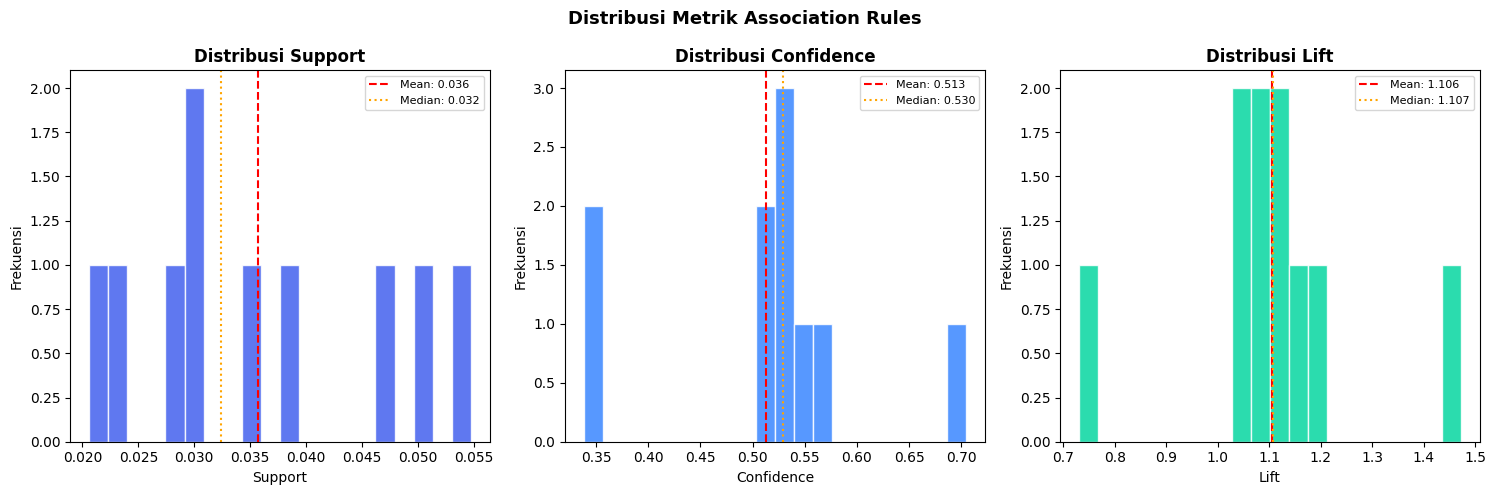

In [22]:
# Distribusi Metrik

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics = [
    ('support',    'Support',    '#4361ee'),
    ('confidence', 'Confidence', '#3a86ff'),
    ('lift',       'Lift',       '#06d6a0'),
]

for ax, (col, label, color) in zip(axes, metrics):
    data = rules_df[col]
    ax.hist(data, bins=20, color=color, edgecolor='white', alpha=0.85)
    ax.axvline(data.mean(), color='red', linestyle='--', linewidth=1.5,
               label=f'Mean: {data.mean():.3f}')
    ax.axvline(data.median(), color='orange', linestyle=':', linewidth=1.5,
               label=f'Median: {data.median():.3f}')
    ax.set_title(f'Distribusi {label}', fontweight='bold')
    ax.set_xlabel(label)
    ax.set_ylabel('Frekuensi')
    ax.legend(fontsize=8)

plt.suptitle('Distribusi Metrik Association Rules', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

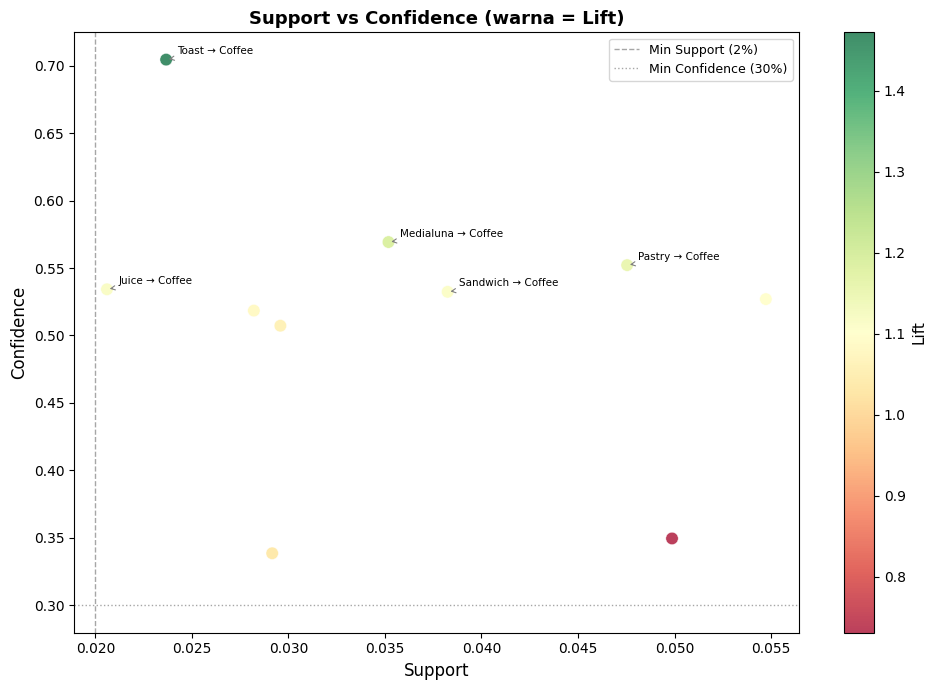

In [23]:
# Scatter Plot

fig, ax = plt.subplots(figsize=(10, 7))

scatter = ax.scatter(
    rules_df['support'],
    rules_df['confidence'],
    c=rules_df['lift'],
    cmap='RdYlGn',
    s=80,
    alpha=0.75,
    edgecolors='white',
    linewidths=0.4
)

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Lift', fontsize=11)

# Beri label pada top-5 rules berdasarkan lift
top5 = rules_df.head(5)
for _, row in top5.iterrows():
    label = f"{row['antecedent_str']} → {row['consequent_str']}"
    ax.annotate(
        label,
        xy=(row['support'], row['confidence']),
        xytext=(8, 4), textcoords='offset points',
        fontsize=7.5, color='black',
        arrowprops=dict(arrowstyle='->', color='gray', lw=0.8)
    )

ax.axvline(MIN_SUPPORT, color='gray', linestyle='--', linewidth=1, alpha=0.7,
           label=f'Min Support ({MIN_SUPPORT:.0%})')
ax.axhline(MIN_CONFIDENCE, color='gray', linestyle=':', linewidth=1, alpha=0.7,
           label=f'Min Confidence ({MIN_CONFIDENCE:.0%})')

ax.set_xlabel('Support', fontsize=12)
ax.set_ylabel('Confidence', fontsize=12)
ax.set_title('Support vs Confidence (warna = Lift)', fontsize=13, fontweight='bold')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

In [24]:
# Top Rules Berdasarkan Tiap Metrik

display_cols = ['antecedent_str', 'consequent_str', 'support', 'confidence', 'lift', 'conviction']

print('=== TOP 10 RULES BERDASARKAN LIFT ===')
print(rules_df[display_cols].head(10).to_string(index=False))

print()
print('=== TOP 10 RULES BERDASARKAN CONFIDENCE ===')
print(rules_df.sort_values('confidence', ascending=False)[display_cols].head(10).to_string(index=False))

print()
print('=== TOP 10 RULES BERDASARKAN SUPPORT ===')
print(rules_df.sort_values('support', ascending=False)[display_cols].head(10).to_string(index=False))

=== TOP 10 RULES BERDASARKAN LIFT ===
antecedent_str consequent_str  support  confidence     lift  conviction
         Toast         Coffee 0.023666    0.704403 1.472431    1.764582
     Medialuna         Coffee 0.035182    0.569231 1.189878    1.210871
        Pastry         Coffee 0.047544    0.552147 1.154168    1.164682
         Juice         Coffee 0.020602    0.534247 1.116750    1.119919
      Sandwich         Coffee 0.038246    0.532353 1.112792    1.115384
          Cake         Coffee 0.054728    0.526958 1.101515    1.102664
       Cookies         Coffee 0.028209    0.518447 1.083723    1.083174
 Hot chocolate         Coffee 0.029583    0.507246 1.060311    1.058553
        Pastry          Bread 0.029160    0.338650 1.034977    1.017305
           Tea         Coffee 0.049868    0.349630 0.730840    0.802014

=== TOP 10 RULES BERDASARKAN CONFIDENCE ===
antecedent_str consequent_str  support  confidence     lift  conviction
         Toast         Coffee 0.023666    0.704403 1.

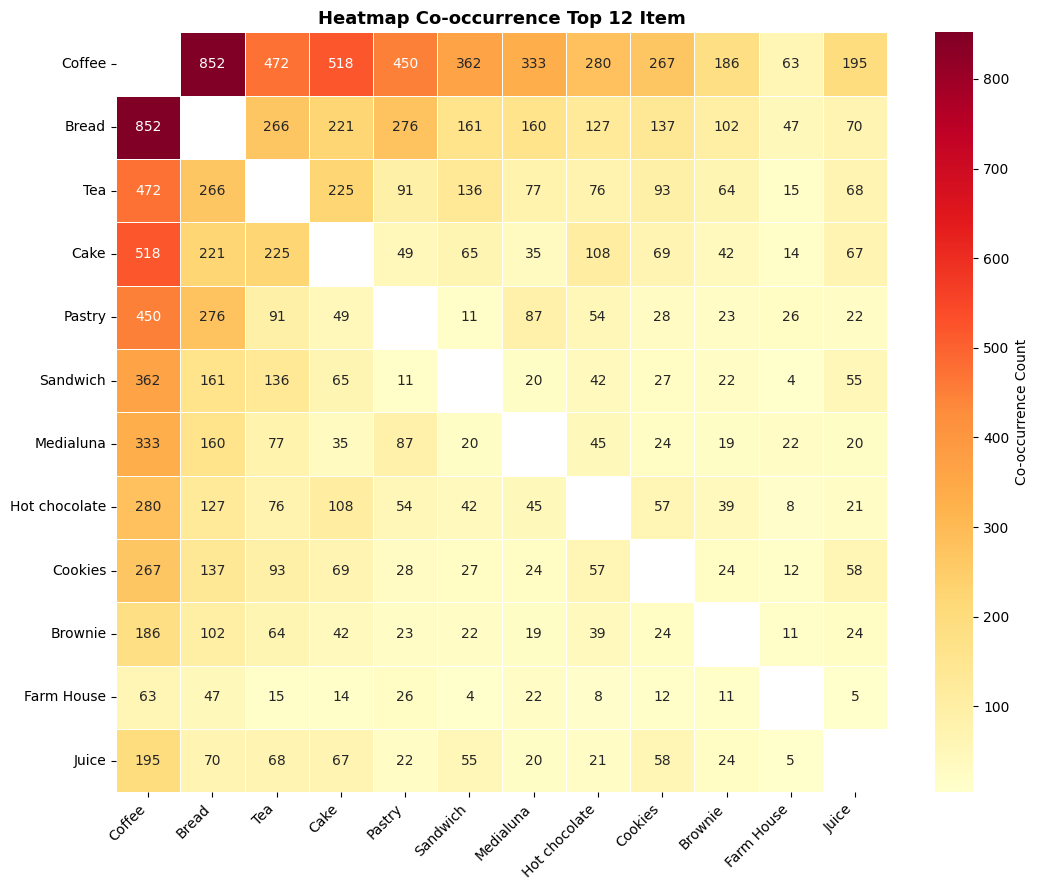

Top 10 pasangan item yang paling sering muncul bersamaan:
Item A        Item B  Co-occurrence
Coffee         Bread            852
Coffee          Cake            518
Coffee           Tea            472
Coffee        Pastry            450
Coffee      Sandwich            362
Coffee     Medialuna            333
Coffee Hot chocolate            280
 Bread        Pastry            276
Coffee       Cookies            267
 Bread           Tea            266


In [25]:
# Heatmap Co-occurrence Item Terpopuler

TOP_N = 12
top_items = item_freq.head(TOP_N).index.tolist()

# Buat matriks co-occurrence
cooccurrence = pd.DataFrame(0, index=top_items, columns=top_items)

for tx_items in transactions:
    tx_top = [item for item in tx_items if item in top_items]
    for i in range(len(tx_top)):
        for j in range(i+1, len(tx_top)):
            cooccurrence.loc[tx_top[i], tx_top[j]] += 1
            cooccurrence.loc[tx_top[j], tx_top[i]] += 1

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.zeros_like(cooccurrence.values, dtype=bool)
np.fill_diagonal(mask, True)  # Sembunyikan diagonal

sns.heatmap(
    cooccurrence,
    annot=True,
    fmt='d',
    cmap='YlOrRd',
    mask=mask,
    linewidths=0.5,
    ax=ax,
    cbar_kws={'label': 'Co-occurrence Count'}
)

ax.set_title(f'Heatmap Co-occurrence Top {TOP_N} Item', fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Pasangan dengan co-occurrence tertinggi
pairs = []
for i in range(len(top_items)):
    for j in range(i+1, len(top_items)):
        pairs.append({
            'Item A': top_items[i],
            'Item B': top_items[j],
            'Co-occurrence': cooccurrence.loc[top_items[i], top_items[j]]
        })
pairs_df = pd.DataFrame(pairs).sort_values('Co-occurrence', ascending=False)
print('Top 10 pasangan item yang paling sering muncul bersamaan:')
print(pairs_df.head(10).to_string(index=False))

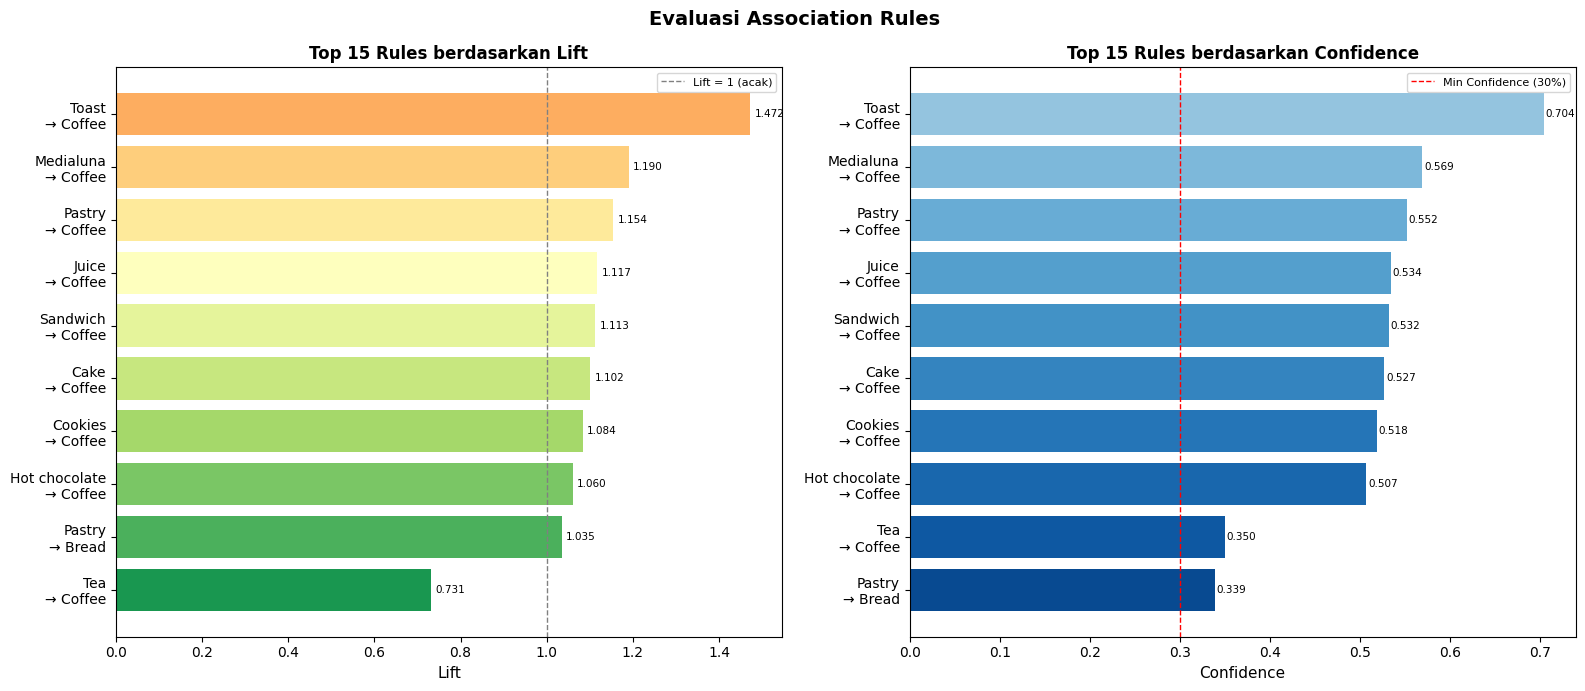

In [26]:
# Visualisasi Top Rules Bar Chart

top_rules = rules_df.head(15).copy()
top_rules['rule'] = top_rules['antecedent_str'] + '\n→ ' + top_rules['consequent_str']

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Bar chart Lift
colors_lift = plt.cm.RdYlGn(np.linspace(0.3, 0.9, len(top_rules)))
bars = axes[0].barh(top_rules['rule'][::-1], top_rules['lift'][::-1],
                    color=colors_lift[::-1])
axes[0].axvline(x=1, color='gray', linestyle='--', linewidth=1, label='Lift = 1 (acak)')
axes[0].set_xlabel('Lift', fontsize=11)
axes[0].set_title('Top 15 Rules berdasarkan Lift', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=8)
for bar, val in zip(bars, top_rules['lift'][::-1]):
    axes[0].text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
                 f'{val:.3f}', va='center', fontsize=7.5)

# Bar chart Confidence
top_conf = rules_df.sort_values('confidence', ascending=False).head(15).copy()
top_conf['rule'] = top_conf['antecedent_str'] + '\n→ ' + top_conf['consequent_str']
colors_conf = plt.cm.Blues(np.linspace(0.4, 0.9, len(top_conf)))
bars2 = axes[1].barh(top_conf['rule'][::-1], top_conf['confidence'][::-1],
                     color=colors_conf[::-1])
axes[1].axvline(x=MIN_CONFIDENCE, color='red', linestyle='--', linewidth=1,
                label=f'Min Confidence ({MIN_CONFIDENCE:.0%})')
axes[1].set_xlabel('Confidence', fontsize=11)
axes[1].set_title('Top 15 Rules berdasarkan Confidence', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=8)
for bar, val in zip(bars2, top_conf['confidence'][::-1]):
    axes[1].text(bar.get_width() + 0.002, bar.get_y() + bar.get_height()/2,
                 f'{val:.3f}', va='center', fontsize=7.5)

plt.suptitle('Evaluasi Association Rules', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

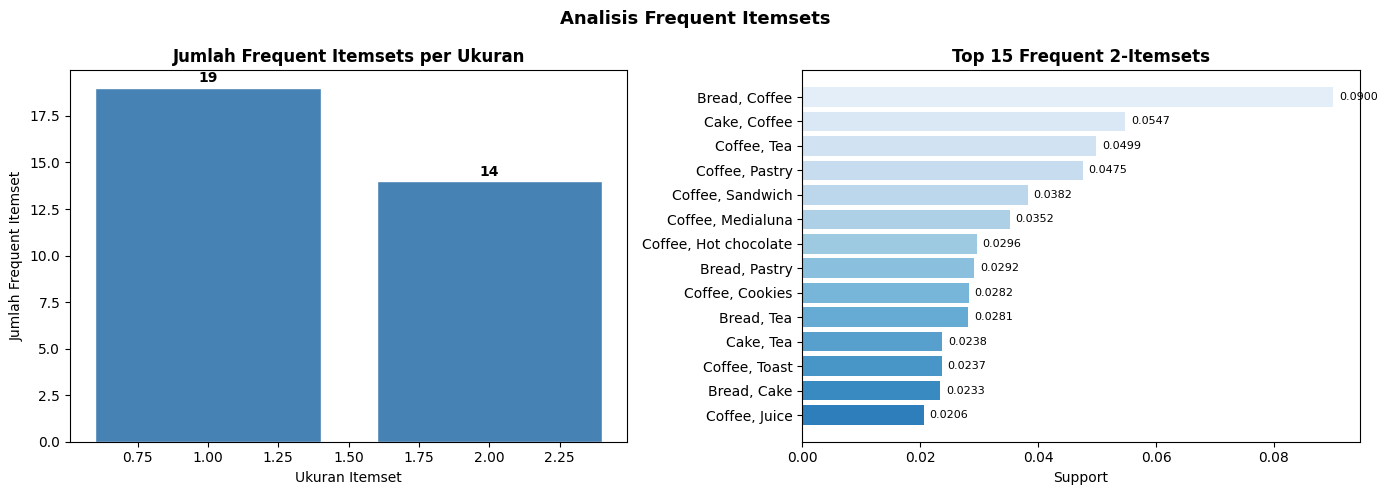

In [27]:
# Visualisasi Frequent Itemsets

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Jumlah frequent itemsets per ukuran
size_count = fi_df.groupby('itemset_size').size()
axes[0].bar(size_count.index, size_count.values,
            color='steelblue', edgecolor='white')
axes[0].set_xlabel('Ukuran Itemset')
axes[0].set_ylabel('Jumlah Frequent Itemset')
axes[0].set_title('Jumlah Frequent Itemsets per Ukuran', fontweight='bold')
for x, y in zip(size_count.index, size_count.values):
    axes[0].text(x, y + 0.3, str(y), ha='center', fontweight='bold')

# Top 15 frequent 2-itemsets
fi_2 = fi_df[fi_df['itemset_size'] == 2].head(15)
axes[1].barh(fi_2['itemset_str'][::-1], fi_2['support'][::-1],
             color=plt.cm.Blues_r(np.linspace(0.3, 0.9, len(fi_2))))
axes[1].set_xlabel('Support')
axes[1].set_title('Top 15 Frequent 2-Itemsets', fontweight='bold')
for i, (val, label) in enumerate(zip(fi_2['support'][::-1], fi_2['itemset_str'][::-1])):
    axes[1].text(val + 0.001, i, f'{val:.4f}', va='center', fontsize=8)

plt.suptitle('Analisis Frequent Itemsets', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Cell 27 — Ringkasan Hasil & Interpretasi Bisnis

In [28]:
# Ringkasan Hasil

print('=' * 65)
print('  RINGKASAN HASIL ASSOCIATION RULE MINING — ECLAT')
print('=' * 65)
print()
print(f'  Dataset     : Bakery Transactions (The Bread Basket)')
print(f'  Algoritma   : ECLAT (Equivalence Class Transformation)')
print(f'  Transaksi   : {TOTAL_TX:,} (setelah dedup)')
print(f'  Item unik   : {len(vertical_db)}')
print()
print(f'  Min Support    : {MIN_SUPPORT:.0%}')
print(f'  Min Confidence : {MIN_CONFIDENCE:.0%}')
print()
print(f'  Frequent Itemsets : {len(fi_df)}')
print(f'  Association Rules : {len(rules_df)}')
print(f'  Rules dengan Lift > 1 : {(rules_df["lift"] > 1).sum()}')
print()
print('─' * 65)
print('  TOP 5 RULES TERKUAT (berdasarkan Lift):')
print('─' * 65)
for i, row in rules_df.head(5).iterrows():
    print(f'  {i+1}. [{row["antecedent_str"]}] → [{row["consequent_str"]}]')
    print(f'     Support={row["support"]:.4f} | Conf={row["confidence"]:.4f} | Lift={row["lift"]:.4f}')
    print()

print('─' * 65)
print('  INTERPRETASI BISNIS:')
print('─' * 65)
print()
print('  1. CROSS-SELLING: Rules dengan confidence tinggi menunjukkan')
print('     peluang promosi silang yang kuat.')
print('     Contoh: pelanggan yang membeli A, sangat mungkin juga membeli B.')
print()
print('  2. PRODUCT BUNDLING: Item-item dalam rules yang memiliki')
print('     lift tinggi cocok dijadikan paket promo (bundle deal).')
print()
print('  3. TATA LETAK TOKO: Item yang sering dibeli bersamaan')
print('     sebaiknya diletakkan berdekatan di toko.')
print()
print('  4. PROGRAM LOYALITAS: Rules dapat menjadi dasar rekomendasi')
print('     personal pada aplikasi loyalty atau struk pembelian.')
print('=' * 65)

  RINGKASAN HASIL ASSOCIATION RULE MINING — ECLAT

  Dataset     : Bakery Transactions (The Bread Basket)
  Algoritma   : ECLAT (Equivalence Class Transformation)
  Transaksi   : 9,465 (setelah dedup)
  Item unik   : 94

  Min Support    : 2%
  Min Confidence : 30%

  Frequent Itemsets : 33
  Association Rules : 10
  Rules dengan Lift > 1 : 9

─────────────────────────────────────────────────────────────────
  TOP 5 RULES TERKUAT (berdasarkan Lift):
─────────────────────────────────────────────────────────────────
  1. [Toast] → [Coffee]
     Support=0.0237 | Conf=0.7044 | Lift=1.4724

  2. [Medialuna] → [Coffee]
     Support=0.0352 | Conf=0.5692 | Lift=1.1899

  3. [Pastry] → [Coffee]
     Support=0.0475 | Conf=0.5521 | Lift=1.1542

  4. [Juice] → [Coffee]
     Support=0.0206 | Conf=0.5342 | Lift=1.1167

  5. [Sandwich] → [Coffee]
     Support=0.0382 | Conf=0.5324 | Lift=1.1128

─────────────────────────────────────────────────────────────────
  INTERPRETASI BISNIS:
──────────────────

In [29]:
# Export Hasil ke CSV

# Export frequent itemsets
fi_export = fi_df[['itemset_str', 'itemset_size', 'support_count', 'support']].copy()
fi_export.to_csv('frequent_itemsets_eclat.csv', index=False)

# Export association rules
rules_export = rules_df[['antecedent_str', 'consequent_str',
                          'support', 'confidence', 'lift', 'conviction']].copy()
rules_export.to_csv('association_rules_eclat.csv', index=False)

print('✅ Hasil berhasil disimpan:')
print('   → frequent_itemsets_eclat.csv')
print('   → association_rules_eclat.csv')
print()
print('Preview association_rules_eclat.csv (top 10):')
rules_export.head(10)

✅ Hasil berhasil disimpan:
   → frequent_itemsets_eclat.csv
   → association_rules_eclat.csv

Preview association_rules_eclat.csv (top 10):


,antecedent_str,consequent_str,support,confidence,lift,conviction
0,Toast,Coffee,0.023666,0.704403,1.472431,1.764582
1,Medialuna,Coffee,0.035182,0.569231,1.189878,1.210871
2,Pastry,Coffee,0.047544,0.552147,1.154168,1.164682
3,Juice,Coffee,0.020602,0.534247,1.116750,1.119919
4,Sandwich,Coffee,0.038246,0.532353,1.112792,1.115384
5,Cake,Coffee,0.054728,0.526958,1.101515,1.102664
6,Cookies,Coffee,0.028209,0.518447,1.083723,1.083174
7,Hot chocolate,Coffee,0.029583,0.507246,1.060311,1.058553
8,Pastry,Bread,0.029160,0.338650,1.034977,1.017305
9,Tea,Coffee,0.049868,0.349630,0.730840,0.802014
